# DCOP Algorithms

**DPOP · DSA · MGM-1 · Max-Sum**

This notebook implements simple plain versions of the above algorithms directly; **it does not use PyDCOP or FRODO**. This means that there are no special optimization of the code and that the code cannot run in a distributed way.

DPOP is optimal (subject to available memory); the other algorithms may find suboptimal solutions.

Currently, it supports only finite-domain **minimization** DCOPs with unary and binary constraints, which are costs.

Every algorithm exposes assignments, objective costs, per-message payloads, and execution traces.

**Assumptions:** one variable per agent; synchronous operations of agents for DSA/MGM-1/Max-Sum; no higher-arity constraints. Message counts are *logical algorithm messages*, not physical network packets.

**Disclaimer:** some parts of the following code have been generated by ChatGPT, please report any problem.

## 1. Dependencies and problem definition



In [21]:
# Only common packages; Colab usually has these already.
%pip -q install pyyaml pandas matplotlib networkx


Note: you may need to restart the kernel to use updated packages.


In [22]:
import itertools, math, random, json, time
from collections import defaultdict
from dataclasses import dataclass, field
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# Choose "inline" to edit YAML below, or "file" to load a YAML file.
PROBLEM_SOURCE = "inline"
YAML_FILE = "/content/my_dcop.yaml"

# Change this YAML to define your problem. Pairwise cost matrices follow the order of the domains.
#
# unary_costs are preferences of the agents
# in pairwise_costs, the first vector is with v1 red, the second is with v1 blue (according to the ordering of the variables and possible values)
#
PROBLEM_YAML = """
name: graph_coloring_two_constraints
variables:
  v1: [red, blue]
  v2: [red, blue]
  v3: [red, blue]
unary_costs:
  v1: [-0.1, 0.1]
  v2: [0.1, -0.1]
  v3: [0.1, -0.1]
pairwise_costs:
  - variables: [v1, v2]
    costs: [[10, 0], [0, 10]]
  - variables: [v2, v3]
    costs: [[10, 0], [0, 10]]
"""

# PROBLEM_YAML = """
# name: triangle_graph_coloring
# variables:
#   A: [red, green, blue]
#   B: [red, green, blue]
#   C: [red, green, blue]
# unary_costs:
#   A: [0, 1, 2]
#   B: [0, 0, 1]
#   C: [0, 0, 0]
# pairwise_costs:
#   - variables: [A, B]
#     costs: [[5, 0, 0], [0, 5, 0], [0, 0, 5]]
#   - variables: [B, C]
#     costs: [[5, 0, 0], [0, 5, 0], [0, 0, 5]]
#   - variables: [A, C]
#     costs: [[5, 0, 0], [0, 5, 0], [0, 0, 5]]
# """


ALGORITHMS = ["DPOP", "DSA", "MGM-1", "Max-Sum"]
# for DPOP we need to specify a root (for the pseudotree)
# DSA and MGM could run forever, so we set a max number of rounds
# Why do we need seed in MGM? Because of random initial values
# Damping of Max-Sum is connected to alpha
PARAMETERS = {
    "DPOP": {"root": "v1"},
    "DSA": {"rounds": 30, "activation_probability": 0.7, "seed": 7},
    "MGM-1": {"rounds": 30, "seed": 7},
    "Max-Sum": {"iterations": 40, "damping": 0.3, "seed": 7},
}
# Maximum entries allowed in any DPOP UTIL table (guard against memory blowups).
DPOP_MAX_TABLE_ENTRIES = 200000
# Maximum number of messages shown for each algorithm.
SHOW_FIRST_MESSAGES = 12


## 2. Utilities: model validation and objective

In [23]:
@dataclass
class DCOP:
    name: str
    domains: dict
    unary: dict
    edges: dict  # (u,v) -> matrix, ordered by variable insertion order
    def cost(self, assignment):  # Calculate the cost of an assignment
        if set(assignment) != set(self.domains):
            raise ValueError("Assignment must specify every variable")
        idx = {v: self.domains[v].index(assignment[v]) for v in self.domains}
        return float(sum(self.unary[v][idx[v]] for v in self.domains) +
                     sum(matrix[idx[u]][idx[v]] for (u,v), matrix in self.edges.items()))
    def neighbors(self):
        adj = {v:set() for v in self.domains}
        for u,v in self.edges:
            adj[u].add(v); adj[v].add(u)
        return {v: sorted(ns) for v,ns in adj.items()}
    def local_cost(self, var, value, assignment):
        i = self.domains[var].index(value)
        total = self.unary[var][i]
        for (u,v), matrix in self.edges.items():
            if u == var and v in assignment:
                total += matrix[i][self.domains[v].index(assignment[v])]
            elif v == var and u in assignment:
                total += matrix[self.domains[u].index(assignment[u])][i]
        return float(total)

def load_problem(source=PROBLEM_SOURCE, inline=PROBLEM_YAML, path=YAML_FILE):
    if source not in ("inline", "file"):
        raise ValueError("PROBLEM_SOURCE must be inline or file")
    if source == "file":
        with open(path, encoding="utf-8") as f: raw = yaml.safe_load(f)
    else:
        raw = yaml.safe_load(inline)
    if not isinstance(raw, dict): raise ValueError("YAML root must be a mapping")
    domains = raw["variables"]
    if not isinstance(domains, dict) or not domains: raise ValueError("Provide nonempty variables mapping")
    for v, values in domains.items():
        if not isinstance(values, list) or not values or len(set(map(str,values))) != len(values):
            raise ValueError(f"Invalid domain for {v}")
    order = {v:i for i,v in enumerate(domains)}
    unary = {v:[0.0]*len(domains[v]) for v in domains}
    for v, values in (raw.get("unary_costs") or {}).items():
        if v not in domains or len(values) != len(domains[v]): raise ValueError(f"Invalid unary costs for {v}")
        unary[v] = [float(x) for x in values]
    edges = {}
    for edge in raw.get("pairwise_costs", []):
        u,v = edge["variables"]
        if u not in domains or v not in domains or u == v: raise ValueError(f"Invalid edge {u},{v}")
        m = edge["costs"]
        if len(m) != len(domains[u]) or any(len(row)!=len(domains[v]) for row in m):
            raise ValueError(f"Wrong matrix dimensions for {u},{v}")
        m = [[float(x) for x in row] for row in m]
        key = (u,v) if order[u] < order[v] else (v,u)
        if key in edges: raise ValueError(f"Duplicate edge {u},{v}")
        edges[key] = m if key == (u,v) else [list(row) for row in zip(*m)]
    return DCOP(str(raw.get("name","custom_dcop")), domains, unary, edges)

# NOTE: file mode is loaded only if selected; no file is needed for the default example.
problem = load_problem()
print("Problem definition")
print("Name:", problem.name, "| Variables:", len(problem.domains), "| Edges:", len(problem.edges))
print("| Domains:", problem.domains)


Problem definition
Name: graph_coloring_two_constraints | Variables: 3 | Edges: 2
| Domains: {'v1': ['red', 'blue'], 'v2': ['red', 'blue'], 'v3': ['red', 'blue']}


## 3. Utilities: trace and message inspection

In [24]:
@dataclass
class RunResult:
    algorithm: str
    assignment: dict
    cost: float
    messages: list = field(default_factory=list)
    history: list = field(default_factory=list)
    details: dict = field(default_factory=dict)

def log_message(messages, step, sender, receiver, kind, payload):
    # Payloads are deliberately preserved so individual messages can be inspected.
    messages.append({"step":step, "sender":str(sender), "receiver":str(receiver),
                     "type":kind, "payload":payload})

def brute_force_optimum(p, max_states=100000):
    states = math.prod(len(d) for d in p.domains.values())
    if states > max_states: return None
    best = None
    for values in itertools.product(*p.domains.values()):
        a = dict(zip(p.domains, values)); cost = p.cost(a)
        if best is None or cost < best[0]: best = (cost, a)
    return best

def initial_assignment(p, rng):
    return {v:rng.choice(domain) for v,domain in p.domains.items()}

def show_messages(result, start=0, count=20):
    print(f"{result.algorithm}: {len(result.messages)} logical messages")
    for i,m in enumerate(result.messages[start:start+count],start):
        print(f"#{i} step={m['step']} {m['sender']} -> {m['receiver']} [{m['type']}]")
        print(json.dumps(m['payload'], indent=2, default=str)[:3000])


## 4. DPOP — DFS pseudotree, UTIL and VALUE phases

In [25]:
def run_dpop(p, root=None, max_entries=200000):
    names = list(p.domains)
    root = root or names[0]
    if root not in p.domains: raise ValueError("Unknown DPOP root")
    adj = p.neighbors(); parent = {}; children = {v:[] for v in names}; visited = set(); order=[]
    # Build a DFS forest, supporting disconnected constraint graphs.
    roots=[]
    def dfs(v, par=None):
        visited.add(v); parent[v]=par; order.append(v)
        if par is not None: children[par].append(v)
        for w in adj[v]:
            if w not in visited: dfs(w,v)
    for r in [root]+[v for v in names if v!=root]:
        if r not in visited: roots.append(r); dfs(r)
    depth={}
    for v in order: depth[v] = 0 if parent[v] is None else depth[parent[v]]+1
    # Each edge factor is assigned to its deeper DFS endpoint.
    assigned_edges={v:[] for v in names}
    for (u,v) in p.edges:
        deeper = u if depth[u]>depth[v] else v
        assigned_edges[deeper].append((u,v))
    messages=[]; util={}; separators={}; policies={}; total_entries=0
    for v in reversed(order):  # Calculate the separators for each variable
        sep = set()
        for u,w in assigned_edges[v]: sep.add(w if u==v else u)
        for ch in children[v]: sep.update(separators[ch])
        sep.discard(v)
        # In DFS, all separator variables are ancestors.
        if any(depth[x]>=depth[v] for x in sep):
            raise RuntimeError("Invalid DFS separator")
        scope = sorted(sep, key=lambda x: names.index(x)); separators[v]=scope
        n_entries = math.prod(len(p.domains[x]) for x in scope+[v])
        total_entries += n_entries
        if n_entries>max_entries or total_entries>max_entries:
            raise MemoryError("DPOP UTIL table too large; reduce domain size or raise DPOP_MAX_TABLE_ENTRIES")
        table={}; policy={}
        for vals in itertools.product(*(p.domains[x] for x in scope)):
            context=dict(zip(scope,vals)); best=(float('inf'),None)
            for value in p.domains[v]:
                a={**context,v:value}; cost=p.unary[v][p.domains[v].index(value)]
                for u,w in assigned_edges[v]:
                    cost += p.edges[(u,w)][p.domains[u].index(a[u])][p.domains[w].index(a[w])]
                for ch in children[v]:
                    key=tuple(a[x] for x in separators[ch]); cost += util[ch][key]
                if cost<best[0]: best=(cost,value)
            table[vals]=best[0]; policy[vals]=best[1]
        util[v]=table; policies[v]=policy
        if parent[v] is not None:
            payload={"separator":scope,"table":[{"context":list(k),"cost":val} for k,val in table.items()]}
            log_message(messages,"UTIL",v,parent[v],"UTIL",payload)
    assignment={}
    def value_phase(v):
        key=tuple(assignment[x] for x in separators[v]); assignment[v]=policies[v][key]
        for ch in children[v]:
            context={x:assignment[x] for x in separators[ch]}
            log_message(messages,"VALUE",v,ch,"VALUE",{"context":context,"parent_value":assignment[v]})
            value_phase(ch)
    for r in roots: value_phase(r)
    cost=p.cost(assignment)
    return RunResult("DPOP",assignment,cost,messages,[{"step":0,"cost":cost}],
                     {"roots":roots,"parent":parent,"children":children,
                      "separators":separators,"util_table_entries":total_entries})



## 5. DSA — Local improvements with stochastic coordination

In [26]:
def run_dsa(p, rounds=30, activation_probability=0.7, seed=7):
    if not 0<=activation_probability<=1: raise ValueError("Probability must be in [0,1]")
    rng=random.Random(seed); a=initial_assignment(p,rng); messages=[]
    history=[{"step":0,"cost":p.cost(a),"assignment":a.copy()}]
    for step in range(1,rounds+1):
        # Agents broadcast current values to their graph neighbors.
        for v,ns in p.neighbors().items():
            for w in ns: log_message(messages,step,v,w,"VALUE",{"value":a[v]})
        next_a=a.copy()
        for v in p.domains:
            options=[(p.local_cost(v,x,a),i,x) for i,x in enumerate(p.domains[v])]
            _,_,best=min(options)
            if p.local_cost(v,best,a)<p.local_cost(v,a[v],a)-1e-12 and rng.random()<activation_probability:
                next_a[v]=best
        a=next_a
        history.append({"step":step,"cost":p.cost(a),"assignment":a.copy()})
    return RunResult("DSA",a,p.cost(a),messages,history,
                     {"rounds":rounds,"activation_probability":activation_probability,"seed":seed})


## 6. MGM-1 — Local improvements with maximum-gain coordination

In [27]:
def run_mgm1(p, rounds=30, seed=7):
    rng=random.Random(seed); a=initial_assignment(p,rng); adj=p.neighbors(); messages=[]
    history=[{"step":0,"cost":p.cost(a),"assignment":a.copy()}]
    for step in range(1,rounds+1):
        for v,ns in adj.items():
            for w in ns: log_message(messages,step,v,w,"VALUE",{"value":a[v]})
        gains={}; choices={}
        for v in p.domains:
            old=p.local_cost(v,a[v],a)
            new,_,value=min((p.local_cost(v,x,a),i,x) for i,x in enumerate(p.domains[v]))
            gains[v]=max(0.0,old-new); choices[v]=value
        for v,ns in adj.items():
            for w in ns: log_message(messages,step,v,w,"GAIN",{"gain":gains[v]})
        next_a=a.copy()
        # Lexicographic tie-breaking prevents adjacent simultaneous changes.
        for v in p.domains:
            if gains[v]>1e-12 and all((gains[v],-list(p.domains).index(v)) >
                    (gains[w],-list(p.domains).index(w)) for w in adj[v]):
                next_a[v]=choices[v]
        a=next_a
        history.append({"step":step,"cost":p.cost(a),"assignment":a.copy()})
    return RunResult("MGM-1",a,p.cost(a),messages,history,{"rounds":rounds,"seed":seed})


## 7. Max-Sum — Factor graph messages

In [28]:
def run_maxsum(p, iterations=40, damping=0.3, seed=7):
    if not 0<=damping<1: raise ValueError("Damping must be in [0,1)")
    if iterations<0: raise ValueError("iterations must be >= 0")
    rng=random.Random(seed); names=list(p.domains)
    # Factors include every unary cost and each pairwise matrix.
    factors={f"unary:{v}":(v,) for v in names}
    for u,v in p.edges: factors[f"pair:{u}|{v}"]=(u,v)
    incident={v:[f for f,scope in factors.items() if v in scope] for v in names}
    vf={(v,f):[0.0]*len(p.domains[v]) for v in names for f in incident[v]}
    fv={(f,v):[0.0]*len(p.domains[v]) for v in names for f in incident[v]}
    messages=[]; history=[]
    def beliefs():
        a={}
        for v in names:
            score=[sum(fv[(f,v)][i] for f in incident[v]) for i in range(len(p.domains[v]))]
            a[v]=p.domains[v][min(range(len(score)),key=lambda i:score[i])]
        return a
    a=beliefs(); history.append({"step":0,"cost":p.cost(a),"assignment":a.copy()})
    def normalize(vec):
        offset=min(vec)
        return [float(x-offset) for x in vec]
    for step in range(1,iterations+1):
        new_vf={}
        for v in names:
            for f in incident[v]:
                raw=[sum(fv[(g,v)][i] for g in incident[v] if g!=f)
                     for i in range(len(p.domains[v]))]
                proposed=normalize(raw)
                new_vf[(v,f)]=[(1-damping)*x+damping*y for x,y in zip(proposed,vf[(v,f)])]
                log_message(messages,step,v,f,"VAR_TO_FACTOR",{"domain":p.domains[v],"values":new_vf[(v,f)]})
        new_fv={}
        for f,scope in factors.items():
            for v in scope:
                if len(scope)==1:
                    raw=p.unary[v][:]
                else:
                    u,w=scope; other=w if v==u else u
                    raw=[]
                    for i in range(len(p.domains[v])):
                        vals=[]
                        for j in range(len(p.domains[other])):
                            edge_cost=p.edges[(u,w)][i][j] if v==u else p.edges[(u,w)][j][i]
                            vals.append(edge_cost+new_vf[(other,f)][j])
                        raw.append(min(vals))
                proposed=normalize(raw)
                new_fv[(f,v)]=[(1-damping)*x+damping*y for x,y in zip(proposed,fv[(f,v)])]
                log_message(messages,step,f,v,"FACTOR_TO_VAR",{"domain":p.domains[v],"values":new_fv[(f,v)]})
        vf,fv=new_vf,new_fv
        a=beliefs(); history.append({"step":step,"cost":p.cost(a),"assignment":a.copy()})
    return RunResult("Max-Sum",a,p.cost(a),messages,history,
                     {"iterations":iterations,"damping":damping,"seed":seed,
                      "note":"Synchronous min-sum updates; beliefs decoded independently, no convergence guarantee"})


## 8. Run experiments and inspect solutions

In [29]:
RUNNERS={"DPOP":run_dpop,"DSA":run_dsa,"MGM-1":run_mgm1,"Max-Sum":run_maxsum}
results={}; rows=[]
for name in ALGORITHMS:
    if name not in RUNNERS: raise ValueError(f"Unknown algorithm: {name}")
    kwargs=PARAMETERS.get(name,{}).copy()
    if name=="DPOP": kwargs["max_entries"]=DPOP_MAX_TABLE_ENTRIES
    started=time.perf_counter()
    try:
        result=RUNNERS[name](problem,**kwargs)
        elapsed=time.perf_counter()-started
        results[name]=result
        rows.append({"algorithm":name,"cost":result.cost,"messages":len(result.messages),
                     "runtime_seconds":elapsed,"assignment":json.dumps(result.assignment)})
    except Exception as exc:
        rows.append({"algorithm":name,"error":repr(exc)})
summary=pd.DataFrame(rows)
display(summary)
optimum=brute_force_optimum(problem)
if optimum:
    print("Brute-force optimum:",optimum[0],"assignment:",optimum[1])
else:
    print("Brute-force check skipped (more than 100,000 joint assignments)")


,algorithm,cost,messages,runtime_seconds,assignment
0,DPOP,-0.1,4,0.000061,"{""v1"": ""red"", ""v2"": ""blue"", ""v3"": ""red""}"
1,DSA,0.1,120,0.000218,"{""v1"": ""blue"", ""v2"": ""red"", ""v3"": ""blue""}"
2,MGM-1,0.1,240,0.000186,"{""v1"": ""blue"", ""v2"": ""red"", ""v3"": ""blue""}"
3,Max-Sum,-0.1,560,0.000887,"{""v1"": ""red"", ""v2"": ""blue"", ""v3"": ""red""}"


Brute-force optimum: -0.1 assignment: {'v1': 'red', 'v2': 'blue', 'v3': 'red'}


In [30]:
# In this case, Max-Sum was guaranteed to be optimal (and it is!) since the graph is acyclic.

In [31]:
# Inspection of DPOP.
SELECTED_ALGORITHM = "DPOP"
if SELECTED_ALGORITHM in results:
    selected=results[SELECTED_ALGORITHM]
    print("Algorithm:",selected.algorithm)
    print("Assignment:",json.dumps(selected.assignment,indent=2))
    print("Total cost:",selected.cost)
    print("Messages:",len(selected.messages))
    print("Algorithm details:",json.dumps(selected.details,indent=2,default=str))
    show_messages(selected, start=0, count=SHOW_FIRST_MESSAGES)
else:
    print("Algorithm not run:",SELECTED_ALGORITHM)


Algorithm: DPOP
Assignment: {
  "v1": "red",
  "v2": "blue",
  "v3": "red"
}
Total cost: -0.1
Messages: 4
Algorithm details: {
  "roots": [
    "v1"
  ],
  "parent": {
    "v1": null,
    "v2": "v1",
    "v3": "v2"
  },
  "children": {
    "v1": [
      "v2"
    ],
    "v2": [
      "v3"
    ],
    "v3": []
  },
  "separators": {
    "v3": [
      "v2"
    ],
    "v2": [
      "v1"
    ],
    "v1": []
  },
  "util_table_entries": 10
}
DPOP: 4 logical messages
#0 step=UTIL v3 -> v2 [UTIL]
{
  "separator": [
    "v2"
  ],
  "table": [
    {
      "context": [
        "red"
      ],
      "cost": -0.1
    },
    {
      "context": [
        "blue"
      ],
      "cost": 0.1
    }
  ]
}
#1 step=UTIL v2 -> v1 [UTIL]
{
  "separator": [
    "v1"
  ],
  "table": [
    {
      "context": [
        "red"
      ],
      "cost": 0.0
    },
    {
      "context": [
        "blue"
      ],
      "cost": 0.0
    }
  ]
}
#2 step=VALUE v1 -> v2 [VALUE]
{
  "context": {
    "v1": "red"
  },
  "parent_va

#Answer the following questions


1.   Look down to the pseudotree built by DPOP. Does it make sense?
2.   Look at the messages that are exchanged between the agents. Are they consistent with the pseudotree?


In [32]:
# Inspection of DSA.
SELECTED_ALGORITHM = "DSA"
if SELECTED_ALGORITHM in results:
    selected=results[SELECTED_ALGORITHM]
    print("Algorithm:",selected.algorithm)
    print("Assignment:",json.dumps(selected.assignment,indent=2))
    print("Total cost:",selected.cost)
    print("Messages:",len(selected.messages))
    print("Algorithm details:",json.dumps(selected.details,indent=2,default=str))
    show_messages(selected, start=0, count=SHOW_FIRST_MESSAGES)
else:
    print("Algorithm not run:",SELECTED_ALGORITHM)

Algorithm: DSA
Assignment: {
  "v1": "blue",
  "v2": "red",
  "v3": "blue"
}
Total cost: 0.1
Messages: 120
Algorithm details: {
  "rounds": 30,
  "activation_probability": 0.7,
  "seed": 7
}
DSA: 120 logical messages
#0 step=1 v1 -> v2 [VALUE]
{
  "value": "blue"
}
#1 step=1 v2 -> v1 [VALUE]
{
  "value": "red"
}
#2 step=1 v2 -> v3 [VALUE]
{
  "value": "red"
}
#3 step=1 v3 -> v2 [VALUE]
{
  "value": "blue"
}
#4 step=2 v1 -> v2 [VALUE]
{
  "value": "blue"
}
#5 step=2 v2 -> v1 [VALUE]
{
  "value": "red"
}
#6 step=2 v2 -> v3 [VALUE]
{
  "value": "red"
}
#7 step=2 v3 -> v2 [VALUE]
{
  "value": "blue"
}
#8 step=3 v1 -> v2 [VALUE]
{
  "value": "blue"
}
#9 step=3 v2 -> v1 [VALUE]
{
  "value": "red"
}
#10 step=3 v2 -> v3 [VALUE]
{
  "value": "red"
}
#11 step=3 v3 -> v2 [VALUE]
{
  "value": "blue"
}


# Answer the following questions


1.   The code below changes the activation probability from a very small value and to a very large value. What is the behavior that you expect?
2.   The code below changes the number of rounds (iterations). What do you expect is this number increases from 0?


In [33]:
resultsdsa={}; rows=[]
resultdsa=run_dsa(problem,activation_probability=0)
resultsdsa[1]=resultdsa
rows.append({"activation_probability":0,"cost":result.cost,"messages":len(resultdsa.messages),
             "assignment":json.dumps(resultdsa.assignment)})
resultdsa=run_dsa(problem,activation_probability=0.1)
resultsdsa[0]=resultdsa
rows.append({"activation_probability":0.1,"cost":result.cost,"messages":len(resultdsa.messages),
             "assignment":json.dumps(resultdsa.assignment)})
resultdsa=run_dsa(problem,activation_probability=0.5)
resultsdsa[1]=resultdsa
rows.append({"activation_probability":0.5,"cost":result.cost,"messages":len(resultdsa.messages),
             "assignment":json.dumps(resultdsa.assignment)})
resultdsa=run_dsa(problem,activation_probability=0.9)
resultsdsa[1]=resultdsa
rows.append({"activation_probability":0.9,"cost":result.cost,"messages":len(resultdsa.messages),
             "assignment":json.dumps(resultdsa.assignment)})
summary=pd.DataFrame(rows)
display(summary)
optimum=brute_force_optimum(problem)
if optimum:
    print("Brute-force optimum:",optimum[0],"assignment:",optimum[1])
else:
    print("Brute-force check skipped (more than 100,000 joint assignments)")

,activation_probability,cost,messages,assignment
0,0.0,-0.1,120,"{""v1"": ""blue"", ""v2"": ""red"", ""v3"": ""blue""}"
1,0.1,-0.1,120,"{""v1"": ""blue"", ""v2"": ""red"", ""v3"": ""blue""}"
2,0.5,-0.1,120,"{""v1"": ""blue"", ""v2"": ""red"", ""v3"": ""blue""}"
3,0.9,-0.1,120,"{""v1"": ""blue"", ""v2"": ""red"", ""v3"": ""blue""}"


Brute-force optimum: -0.1 assignment: {'v1': 'red', 'v2': 'blue', 'v3': 'red'}


In [34]:
# Optimal by chance!

In [35]:
resultsdsa={}; rows=[]
resultdsa=run_dsa(problem,rounds=0)
resultsdsa[1]=resultdsa
rows.append({"rounds":0,"cost":result.cost,"messages":len(resultdsa.messages),
             "assignment":json.dumps(resultdsa.assignment)})
resultdsa=run_dsa(problem,rounds=10)
resultsdsa[0]=resultdsa
rows.append({"rounds":10,"cost":result.cost,"messages":len(resultdsa.messages),
             "assignment":json.dumps(resultdsa.assignment)})
resultdsa=run_dsa(problem,rounds=20)
resultsdsa[1]=resultdsa
rows.append({"rounds":20,"cost":result.cost,"messages":len(resultdsa.messages),
             "assignment":json.dumps(resultdsa.assignment)})
summary=pd.DataFrame(rows)
display(summary)
optimum=brute_force_optimum(problem)
if optimum:
    print("Brute-force optimum:",optimum[0],"assignment:",optimum[1])
else:
    print("Brute-force check skipped (more than 100,000 joint assignments)")

,rounds,cost,messages,assignment
0,0,-0.1,0,"{""v1"": ""blue"", ""v2"": ""red"", ""v3"": ""blue""}"
1,10,-0.1,40,"{""v1"": ""blue"", ""v2"": ""red"", ""v3"": ""blue""}"
2,20,-0.1,80,"{""v1"": ""blue"", ""v2"": ""red"", ""v3"": ""blue""}"


Brute-force optimum: -0.1 assignment: {'v1': 'red', 'v2': 'blue', 'v3': 'red'}


In [36]:
# Inspection of MGM-1.
SELECTED_ALGORITHM = "MGM-1"
if SELECTED_ALGORITHM in results:
    selected=results[SELECTED_ALGORITHM]
    print("Algorithm:",selected.algorithm)
    print("Assignment:",json.dumps(selected.assignment,indent=2))
    print("Total cost:",selected.cost)
    print("Messages:",len(selected.messages))
    print("Algorithm details:",json.dumps(selected.details,indent=2,default=str))
    show_messages(selected, start=0, count=SHOW_FIRST_MESSAGES)
else:
    print("Algorithm not run:",SELECTED_ALGORITHM)

Algorithm: MGM-1
Assignment: {
  "v1": "blue",
  "v2": "red",
  "v3": "blue"
}
Total cost: 0.1
Messages: 240
Algorithm details: {
  "rounds": 30,
  "seed": 7
}
MGM-1: 240 logical messages
#0 step=1 v1 -> v2 [VALUE]
{
  "value": "blue"
}
#1 step=1 v2 -> v1 [VALUE]
{
  "value": "red"
}
#2 step=1 v2 -> v3 [VALUE]
{
  "value": "red"
}
#3 step=1 v3 -> v2 [VALUE]
{
  "value": "blue"
}
#4 step=1 v1 -> v2 [GAIN]
{
  "gain": 0.0
}
#5 step=1 v2 -> v1 [GAIN]
{
  "gain": 0.0
}
#6 step=1 v2 -> v3 [GAIN]
{
  "gain": 0.0
}
#7 step=1 v3 -> v2 [GAIN]
{
  "gain": 0.0
}
#8 step=2 v1 -> v2 [VALUE]
{
  "value": "blue"
}
#9 step=2 v2 -> v1 [VALUE]
{
  "value": "red"
}
#10 step=2 v2 -> v3 [VALUE]
{
  "value": "red"
}
#11 step=2 v3 -> v2 [VALUE]
{
  "value": "blue"
}


In [37]:
# Inspection of Max-Sum.
SELECTED_ALGORITHM = "Max-Sum"
if SELECTED_ALGORITHM in results:
    selected=results[SELECTED_ALGORITHM]
    print("Algorithm:",selected.algorithm)
    print("Assignment:",json.dumps(selected.assignment,indent=2))
    print("Total cost:",selected.cost)
    print("Messages:",len(selected.messages))
    print("Algorithm details:",json.dumps(selected.details,indent=2,default=str))
    show_messages(selected, start=0, count=SHOW_FIRST_MESSAGES)
else:
    print("Algorithm not run:",SELECTED_ALGORITHM)

Algorithm: Max-Sum
Assignment: {
  "v1": "red",
  "v2": "blue",
  "v3": "red"
}
Total cost: -0.1
Messages: 560
Algorithm details: {
  "iterations": 40,
  "damping": 0.3,
  "seed": 7,
  "note": "Synchronous min-sum updates; beliefs decoded independently, no convergence guarantee"
}
Max-Sum: 560 logical messages
#0 step=1 v1 -> unary:v1 [VAR_TO_FACTOR]
{
  "domain": [
    "red",
    "blue"
  ],
  "values": [
    0.0,
    0.0
  ]
}
#1 step=1 v1 -> pair:v1|v2 [VAR_TO_FACTOR]
{
  "domain": [
    "red",
    "blue"
  ],
  "values": [
    0.0,
    0.0
  ]
}
#2 step=1 v2 -> unary:v2 [VAR_TO_FACTOR]
{
  "domain": [
    "red",
    "blue"
  ],
  "values": [
    0.0,
    0.0
  ]
}
#3 step=1 v2 -> pair:v1|v2 [VAR_TO_FACTOR]
{
  "domain": [
    "red",
    "blue"
  ],
  "values": [
    0.0,
    0.0
  ]
}
#4 step=1 v2 -> pair:v2|v3 [VAR_TO_FACTOR]
{
  "domain": [
    "red",
    "blue"
  ],
  "values": [
    0.0,
    0.0
  ]
}
#5 step=1 v3 -> unary:v3 [VAR_TO_FACTOR]
{
  "domain": [
    "red",
    "blue

## 9. Visualize problem, costs, and message traffic

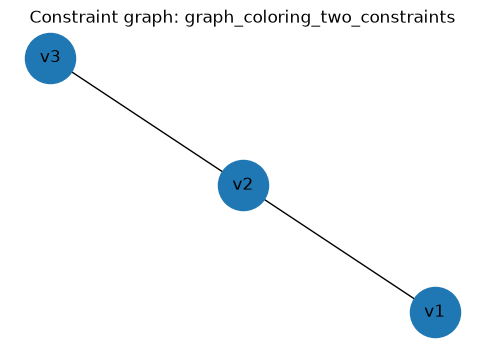

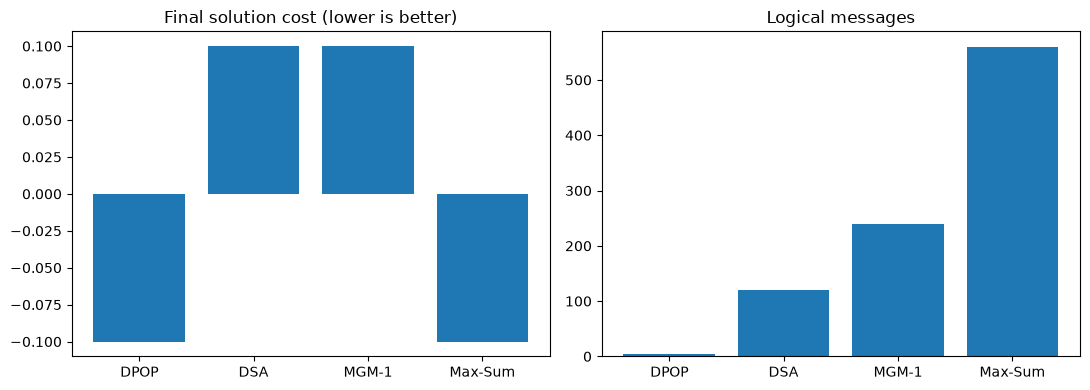

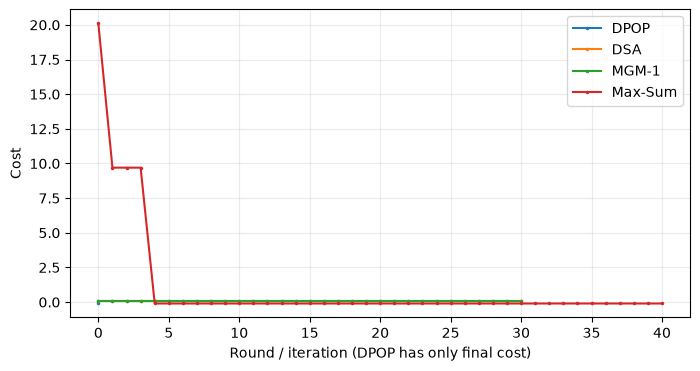

In [38]:
G=nx.Graph(); G.add_nodes_from(problem.domains); G.add_edges_from(problem.edges)
plt.figure(figsize=(6,4)); nx.draw_networkx(G,with_labels=True,node_size=1300)
plt.title(f"Constraint graph: {problem.name}"); plt.axis("off"); plt.show()

if results:
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    axes[0].bar(list(results),[r.cost for r in results.values()]); axes[0].set_title("Final solution cost (lower is better)")
    axes[1].bar(list(results),[len(r.messages) for r in results.values()]); axes[1].set_title("Logical messages")
    plt.tight_layout(); plt.show()
    plt.figure(figsize=(8,4))
    for name,r in results.items():
        plt.plot([h['step'] for h in r.history],[h['cost'] for h in r.history],label=name,marker='.',markersize=3)
    plt.xlabel("Round / iteration (DPOP has only final cost)"); plt.ylabel("Cost"); plt.legend(); plt.grid(alpha=.25); plt.show()


# Answer the following questions


1.   How do you explain that the number of messages exchanged by MGM-1 is double than the number of messages exchanged by DSA?
> Because in DSA we only send value, in MGM both value and gain
2.   How do you explain the behavior over the rounds (iterations) of DSA, when compared to that of MGM-1?
3.   Would have you expected that Max-Sum finds the optimal solution in this case?



## 10. Inspect the DFS pseudotree constructed by DPOP

The diagram below shows the psuedotree used by DPOP. Solid arrows are DFS tree edges (parent → child); dashed orange curves are constraint edges that are not part of the tree (pseudoedges). Each node shows its depth and separator. Disconnected problems appear as a DFS forest.

To change the DFS root, edit `PARAMETERS["DPOP"]["root"]` in the configuration cell and rerun the experiment. The pseudotree can change the size of UTIL tables and the messages exchanged, even when the optimal cost stays the same.

In [39]:
# Visualize the exact DFS forest stored in the DPOP result.
# Note: the following code is not yet polished!
SHOW_DPOP_SEPARATORS = True

if "DPOP" not in results:
    print("Run DPOP in the experiment cell to display its DFS pseudotree.")
else:
    dpop = results["DPOP"]
    parent = dpop.details["parent"]
    children = dpop.details["children"]
    roots = dpop.details["roots"]
    separators = dpop.details["separators"]
    depth = {}
    levels = {}
    x_positions = {}

    # Leaf-to-root layout: place parents over their children's centers.
    next_leaf_x = [0]
    def layout(v, level):
        depth[v] = level
        levels.setdefault(level, []).append(v)
        if not children[v]:
            x_positions[v] = next_leaf_x[0]
            next_leaf_x[0] += 1
        else:
            for child in children[v]:
                layout(child, level + 1)
            x_positions[v] = sum(x_positions[c] for c in children[v]) / len(children[v])
    for root in roots:
        layout(root, 0)
        next_leaf_x[0] += 1  # Space between disconnected components.

    positions = {v: (x_positions[v], -depth[v]) for v in parent}
    tree_edges = [(par, v) for v, par in parent.items() if par is not None]
    tree_edge_sets = {frozenset(e) for e in tree_edges}
    back_edges = [(u, v) for u, v in problem.edges if frozenset((u, v)) not in tree_edge_sets]
    T = nx.DiGraph()
    T.add_nodes_from(problem.domains)
    T.add_edges_from(tree_edges)

    tree_rows = [{"variable": v, "parent": parent[v] or "(root)",
                  "depth": depth[v], "children": ", ".join(children[v]) or "—",
                  "separator": ", ".join(separators[v]) or "∅"}
                 for v in parent]
    display(pd.DataFrame(tree_rows))
    print(f"DFS tree edges: {len(tree_edges)} | Non-tree constraint edges: {len(back_edges)}")
    if SHOW_DPOP_SEPARATORS:
        print("Separators list ancestor variables that a node's UTIL message depends on.")


,variable,parent,depth,children,separator
0,v1,(root),0,v2,∅
1,v2,v1,1,v3,v1
2,v3,v2,2,—,v2


DFS tree edges: 2 | Non-tree constraint edges: 0
Separators list ancestor variables that a node's UTIL message depends on.


## 11. Export assignments, traces, and results

In [40]:
from pathlib import Path
OUTPUT_DIR=Path("/content/dcop_results" if Path("/content").exists() else "dcop_results")
OUTPUT_DIR.mkdir(exist_ok=True,parents=True)
summary.to_csv(OUTPUT_DIR/"summary.csv",index=False)
for name,r in results.items():
    slug=name.lower().replace("-","_").replace(" ","_")
    (OUTPUT_DIR/f"{slug}_solution.json").write_text(json.dumps({"assignment":r.assignment,"cost":r.cost,"details":r.details},indent=2,default=str))
    (OUTPUT_DIR/f"{slug}_messages.json").write_text(json.dumps(r.messages,indent=2,default=str))
    pd.DataFrame(r.history).to_csv(OUTPUT_DIR/f"{slug}_history.csv",index=False)
print("Results saved in:",OUTPUT_DIR.resolve())
print(*sorted(p.name for p in OUTPUT_DIR.iterdir()),sep="\n")


Results saved in: /Users/francesco/LDocuments/mas/practice6/dcop_results
dpop_history.csv
dpop_messages.json
dpop_solution.json
dsa_history.csv
dsa_messages.json
dsa_solution.json
max_sum_history.csv
max_sum_messages.json
max_sum_solution.json
mgm_1_history.csv
mgm_1_messages.json
mgm_1_solution.json
summary.csv


## 12. Hands on

Try to do the following:


1.   Solve the graph coloring problem formulated as:
```
PROBLEM_YAML = """
name: triangle_graph_coloring
variables:
  A: [red, green, blue]
  B: [red, green, blue]
  C: [red, green, blue]
unary_costs:
  A: [0, 1, 2]
  B: [0, 0, 1]
  C: [0, 0, 0]
pairwise_costs:
  - variables: [A, B]
    costs: [[5, 0, 0], [0, 5, 0], [0, 0, 5]]
  - variables: [B, C]
    costs: [[5, 0, 0], [0, 5, 0], [0, 0, 5]]
  - variables: [A, C]
    costs: [[5, 0, 0], [0, 5, 0], [0, 0, 5]]
"""
```

2.   Formulate and solve the problem in the figure.

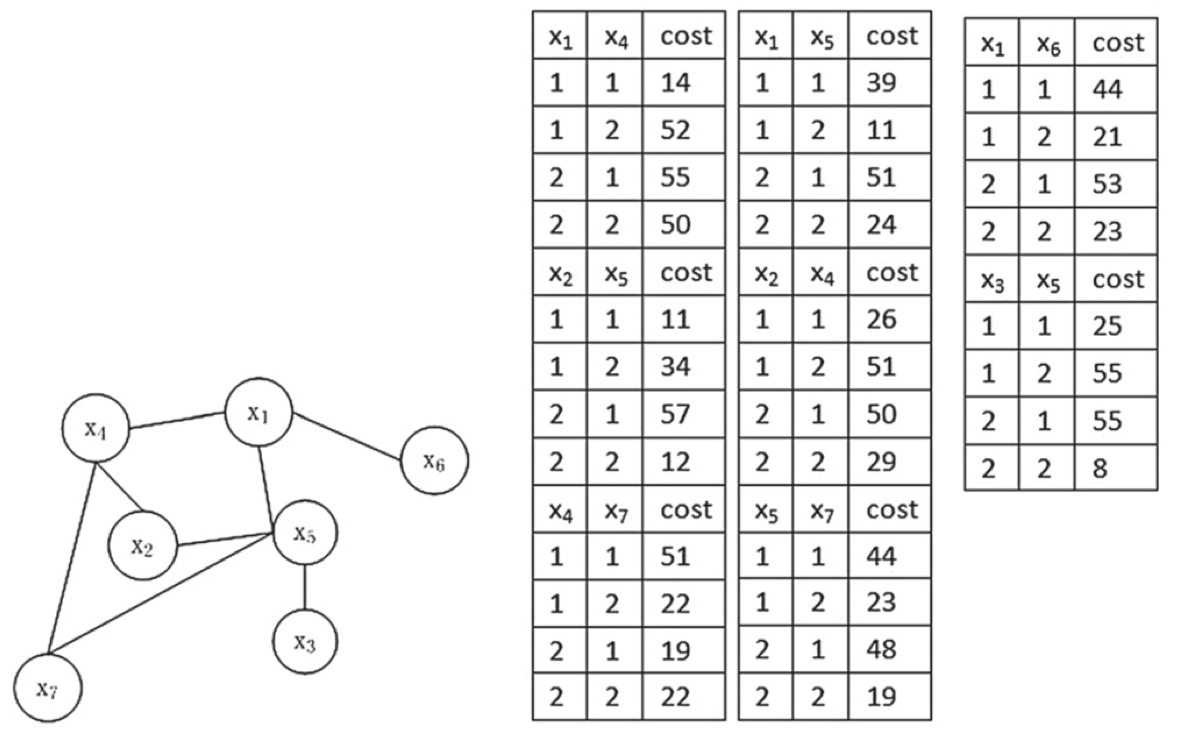


## Notes

- **DPOP** computes an optimal solution using a depth-first pseudotree, UTIL tables, and VALUE propagation. Its memory usage can be exponential in induced width. The logged VALUE message carries the separator context; in a full networked implementation, ancestor assignments must be available to descendants through the pseudotree communication protocol.
- **DSA** uses synchronous rounds and an activation probability for strictly improving moves; different seeds can yield different local minima.
- **MGM-1** exchanges VALUE and GAIN messages and permits a change only when its gain strictly outranks every neighbor (deterministic tie-breaking). It is a one-variable-per-agent, synchronous simulation.
- **Max-Sum** uses a minimization (min-sum) convention, normalization, and optional damping. Loopy graphs may oscillate; the final independent belief assignment is not necessarily optimal.
- **Message counts are not directly comparable as communication costs:** DPOP UTIL payloads may be large tables, while other algorithms exchange shorter repeated messages. Inspect `messages` to compare actual payloads.
- To upload a YAML file in Colab, use `from google.colab import files; files.upload()`, set `PROBLEM_SOURCE="file"`, and point `YAML_FILE` to the uploaded filename. Then rerun from the model-loading cell onward.
